# Séance 9 — Canevas du projet et préparation de la soutenance

Ce notebook n'est pas un atelier : c'est le **squelette de votre rendu**. Remplacez chaque
section par votre travail. La structure suit l'ordre de la soutenance, ce qui vous évite
de refaire le plan au dernier moment.

---

## Identification

| | |
|---|---|
| Groupe | *numéro et noms* |
| Sujet | *domaine attribué, voir la fiche Sujets de projet* |
| Question traitée | *reprise de la fiche, ou reformulée si vous l'affinez* |
| Date de soutenance | *jour 5, après-midi* |

> **Format.** 15 minutes de présentation, 10 minutes de questions devant un jury unique.
> Les questions sont posées individuellement : chaque membre du groupe doit pouvoir
> répondre sur l'intégralité du travail, y compris les parties qu'il n'a pas présentées.
> **Dépôt du rendu : jour 5, 13 h 30.**

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  evenements_volumineux.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


> **Votre jeu de données vous est fourni.** Chaque groupe reçoit un domaine différent,
> avec ses propres anomalies : les chiffres, les pièges et les décisions à justifier ne
> sont pas les mêmes d'un groupe à l'autre. Comparer vos *méthodes* entre groupes est
> encouragé ; comparer vos *résultats* ne vous mènera nulle part.

> **Aucun sujet ne dit quelles anomalies son jeu contient.** Les trouver est la première
> partie du travail, et la première chose que le jury vérifiera. Commencez par appliquer
> votre `profile_dataframe` du jour 1 : elle a été écrite pour cela.

---
## 1. Contexte (2 min de présentation)

**À renseigner :** l'origine des données, ce qu'elles décrivent, la période couverte, et la
question à laquelle le jeu préparé doit permettre de répondre.

*Votre texte :*

Notre projet porte sur l'analyse des délivrances de produits de santé dans un réseau d'officines.

Les données proviennent de quatre fichiers CSV mis à disposition dans le cadre du projet : delivrances.csv, patients.csv, produits.csv et officines.csv.

Ces fichiers contiennent les informations sur les délivrances (dates, quantités, montants remboursés, types d'ordonnance et statuts), les patients, les produits et les officines.

Le fichier principal comporte 21 973 enregistrements. Les données de délivrance couvrent la période du 1er janvier 2023 au 30 décembre 2024, d'après les dates qui ont pu être interprétées.

Notre objectif est de préparer un jeu de données propre, fiable et exploitable pour analyser l'activité de délivrance selon les périodes, les produits, les profils de patients et les officines.

Comment évoluent les délivrances et les montants remboursés selon le temps, les familles de produits, les segments de patients et les officines ?

In [3]:
# Chargement de la source brute. Aucun nettoyage à ce stade :
# on montre l'état initial, c'est lui qui donne sa valeur au travail qui suit.

# Indiquez ici le dossier de VOTRE groupe (voir la fiche Sujets de projet).
import pandas as pd

# Dossier de notre projet
GROUP_DIR = ROOT / 'data' / 'projets' / 'groupe_06_pharmacie'
RAW_DIR = GROUP_DIR / 'raw'

# Afficher les fichiers reçus
print('Fichiers reçus :')
for path in sorted(RAW_DIR.glob('*.csv')):
    size_kb = path.stat().st_size / 1024
    print(f'  {path.name:<28} {size_kb:>8.0f} Ko')

# Charger la table principale (table de faits)
delivrances = pd.read_csv(RAW_DIR / 'delivrances.csv')

# Charger les référentiels
patients = pd.read_csv(RAW_DIR / 'patients.csv')
produits = pd.read_csv(RAW_DIR / 'produits.csv')
officines = pd.read_csv(RAW_DIR / 'officines.csv')

# Afficher les premières lignes de chaque table
print('\n--- DÉLIVRANCES ---')
display(delivrances.head())

print('\n--- PATIENTS ---')
display(patients.head())

print('\n--- PRODUITS ---')
display(produits.head())

print('\n--- OFFICINES ---')
display(officines.head())

# La table principale est la plus volumineuse : les autres sont des référentiels.
# TODO : charger la table de faits et les référentiels, puis afficher un head()

Fichiers reçus :
  delivrances.csv                  1743 Ko
  officines.csv                       1 Ko
  patients.csv                      158 Ko
  produits.csv                       17 Ko

--- DÉLIVRANCES ---


,id_delivrance,date_evenement,id_patient,id_produit,id_officine,boites_delivrees,duree_traitement_jours,montant_rembourse_eur,type_ordonnance,statut
0,DLV0019648,23 Dec 2024,PAT02426,PRD0215,OFF02,2,NaN,241.46,hopital,refuse
1,DLV0003144,25 Feb 2024,PAT03326,PRD0086,OFF99,2,44.0,191.57,medecin_ville,delivre
2,DLV0020284,18/01/2024,PAT03191,PRD0279,OFF09,4,12.0,207.29,hopital,delivre
3,DLV0019757,2024/02/09 15:51,PAT00762,PRD0305,OFF08,4,83.0,155.12,hopital,delivre
4,DLV0000462,09 Dec 2023,PAT00238,PRD0178,OFF03,2,18.0,320.84,renouvellement,delivre



--- PATIENTS ---


,id_patient,date_creation,segment,ville,age
0,PAT00001,2020-11-04,particulier,Nantes,66.0
1,PAT00002,2022-01-21,professionnel,Toulouse,34.0
2,PAT00003,2020-12-13,association,Paris,60.0
3,PAT00004,2019-06-29,professionnel,TOULOUSE,57.0
4,PAT00005,2023-05-09,professionnel,Strasbourg,42.0



--- PRODUITS ---


,id_produit,libelle,famille,sous_famille,cout_reference_eur
0,PRD0001,Del-0001,Famille B,Famille B / variante 2,257.53
1,PRD0002,Del-0002,Famille C,Famille C / variante 3,278.72
2,PRD0003,Del-0003,Famille D,Famille D / variante 4,187.90
3,PRD0004,Del-0004,Famille E,Famille E / variante 5,100.40
4,PRD0005,Del-0005,Famille A,Famille A / variante 6,78.00



--- OFFICINES ---


,id_officine,nom_site,ville,region,capacite
0,OFF01,Site Paris,Paris,Ile-de-France,722
1,OFF02,Site Lyon,Lyon,Auvergne-Rhone-Alpes,127
2,OFF03,Site Marseille,Marseille,PACA,234
3,OFF04,Site Lille,Lille,Hauts-de-France,582
4,OFF05,Site Bordeaux,Bordeaux,Nouvelle-Aquitaine,202


---
## 2. Diagnostic (3 min)

Appliquez votre fonction `profile_dataframe` de la séance 2, puis **quantifiez** chaque
anomalie. Un diagnostic sans chiffre n'est pas un diagnostic.

In [4]:
import sys
sys.path.insert(0, str(ROOT / 'src'))

from exploration import profile_dataframe

# Diagnostic de la table principale
# profile_dataframe(delivrances, name='Délivrances')

# Diagnostic des référentiels
# profile_dataframe(patients, name='Patients')
# profile_dataframe(produits, name='Produits')
# profile_dataframe(officines, name='Officines')

# Diagnostic chiffré des anomalies du projet pharmacie

import pandas as pd

# ==========================================================
# 1. Définir les règles automatiques de gravité
# ==========================================================

def calculer_gravite(pourcentage, impact):
    """
    Gravité calculée à partir de :
    - la fréquence de l'anomalie (en %)
    - son impact métier (1 = faible, 2 = moyen, 3 = fort)
    """

    if pourcentage < 1:
        score_frequence = 1
    elif pourcentage < 5:
        score_frequence = 2
    elif pourcentage < 10:
        score_frequence = 3
    else:
        score_frequence = 4

    score_total = score_frequence + impact

    if score_total <= 3:
        return "Faible"
    elif score_total <= 5:
        return "Moyenne"
    else:
        return "Élevée"


def ajouter_anomalie(resultats, nom, colonne, nombre,
                    total, impact, traitement, justification):

    pourcentage = (nombre / total * 100) if total else 0

    resultats.append({
        "Anomalie": nom,
        "Colonne": colonne,
        "Ampleur": (
            f"{int(nombre)} lignes "
            f"({pourcentage:.2f} %)".replace(".", ",")
        ),
        "Gravité": calculer_gravite(pourcentage, impact),
        "Traitement retenu": traitement,
        "Justification": justification
    })


# ==========================================================
# 2. Calculer les anomalies sur les données brutes
# ==========================================================

n_d = len(delivrances)
n_p = len(patients)
n_pr = len(produits)

resultats = []

# Dates manquantes ou non interprétables
dates_converties = pd.to_datetime(
    delivrances["date_evenement"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

dates_invalides = dates_converties.isna().sum()

# Durées manquantes
durees_manquantes = (
    delivrances["duree_traitement_jours"].isna().sum()
)

# Montants au format texte
montants = delivrances["montant_rembourse_eur"]

montants_textuels = (
    montants.notna()
    & pd.to_numeric(montants, errors="coerce").isna()
).sum()

# Doublons stricts
doublons = delivrances.duplicated().sum()

# Clés produits orphelines
produits_inconnus = (
    delivrances["id_produit"].notna()
    & ~delivrances["id_produit"].isin(produits["id_produit"])
).sum()

# Âges aberrants
ages = pd.to_numeric(patients["age"], errors="coerce")

ages_aberrants = (
    (ages < 0) | (ages > 120)
).sum()

# Âges manquants
ages_manquants = ages.isna().sum()

# Quantités nulles
quantites = pd.to_numeric(
    delivrances["boites_delivrees"],
    errors="coerce"
)

quantites_nulles = (quantites == 0).sum()

# Coûts manquants
couts_manquants = (
    produits["cout_reference_eur"].isna().sum()
)

# Textes non normalisés
statuts = delivrances["statut"].astype("string")
statuts_non_normalises = (
    statuts.notna()
    & statuts.ne(statuts.str.strip().str.lower())
).fillna(False).sum()

ordonnances = delivrances["type_ordonnance"].astype("string")
ordonnances_non_normalisees = (
    ordonnances.notna()
    & ordonnances.ne(ordonnances.str.strip().str.lower())
).fillna(False).sum()


# ==========================================================
# 3. Ajouter les anomalies et calculer leur gravité
# Impact : 1 = faible, 2 = moyen, 3 = fort
# ==========================================================

ajouter_anomalie(
    resultats, "Dates invalides ou manquantes",
    "date_evenement", dates_invalides, n_d, 3,
    "Exclure des analyses temporelles si irrécupérables",
    "Empêche les analyses chronologiques"
)

ajouter_anomalie(
    resultats, "Durées manquantes",
    "duree_traitement_jours", durees_manquantes, n_d, 2,
    "Conserver les valeurs manquantes",
    "Réduit la fiabilité des analyses de durée"
)

ajouter_anomalie(
    resultats, "Montants au format texte",
    "montant_rembourse_eur", montants_textuels, n_d, 3,
    "Nettoyer EUR et les virgules, puis convertir",
    "Empêche les calculs fiables de montants"
)

ajouter_anomalie(
    resultats, "Doublons stricts",
    "Toutes les colonnes", doublons, n_d, 3,
    "Supprimer après vérification",
    "Risque de compter plusieurs fois une délivrance"
)

ajouter_anomalie(
    resultats, "Produits inconnus",
    "id_produit", produits_inconnus, n_d, 3,
    "Conserver et signaler les références inconnues",
    "Risque de perte de lignes lors des jointures"
)

ajouter_anomalie(
    resultats, "Âges aberrants",
    "age", ages_aberrants, n_p, 3,
    "Remplacer les âges impossibles par NaN",
    "Fausse les statistiques sur les patients"
)

ajouter_anomalie(
    resultats, "Âges manquants",
    "age", ages_manquants, n_p, 2,
    "Conserver ou imputer si nécessaire",
    "Réduit la précision des analyses démographiques"
)

ajouter_anomalie(
    resultats, "Quantités nulles",
    "boites_delivrees", quantites_nulles, n_d, 2,
    "Vérifier les statuts avant toute correction",
    "Peut correspondre à une délivrance non réalisée"
)

ajouter_anomalie(
    resultats, "Coûts manquants",
    "cout_reference_eur", couts_manquants, n_pr, 2,
    "Conserver les valeurs manquantes",
    "Limite les analyses utilisant le coût"
)

ajouter_anomalie(
    resultats, "Statuts non normalisés",
    "statut", statuts_non_normalises, n_d, 2,
    "Supprimer les espaces et passer en minuscules",
    "Crée plusieurs catégories pour un même statut"
)

ajouter_anomalie(
    resultats, "Ordonnances non normalisées",
    "type_ordonnance", ordonnances_non_normalisees, n_d, 2,
    "Supprimer les espaces et passer en minuscules",
    "Fausse les regroupements par type d'ordonnance"
)


# ==========================================================
# 4. Afficher le tableau demandé par le professeur
# ==========================================================

tableau_anomalies = pd.DataFrame(resultats)

colonnes_demandees = [
    "Anomalie",
    "Colonne",
    "Ampleur",
    "Gravité",
    "Traitement retenu"
]

print("DIAGNOSTIC AUTOMATIQUE — PROJET PHARMACIE")
print(f"Délivrances : {n_d} lignes")
print(f"Patients    : {n_p} lignes")
print(f"Produits    : {n_pr} lignes")

display(tableau_anomalies[colonnes_demandees])

# Afficher aussi les justifications de gravité
print("\nJUSTIFICATION DES RISQUES")
display(
    tableau_anomalies[
        ["Anomalie", "Gravité", "Justification"]
    ]
)

DIAGNOSTIC AUTOMATIQUE — PROJET PHARMACIE
Délivrances : 21973 lignes
Patients    : 3455 lignes
Produits    : 310 lignes


,Anomalie,Colonne,Ampleur,Gravité,Traitement retenu
0,Dates invalides ou manquantes,date_evenement,"440 lignes (2,00 %)",Moyenne,Exclure des analyses temporelles si irrécupéra...
1,Durées manquantes,duree_traitement_jours,"2204 lignes (10,03 %)",Élevée,Conserver les valeurs manquantes
2,Montants au format texte,montant_rembourse_eur,"1537 lignes (6,99 %)",Élevée,"Nettoyer EUR et les virgules, puis convertir"
3,Doublons stricts,Toutes les colonnes,"190 lignes (0,86 %)",Moyenne,Supprimer après vérification
4,Produits inconnus,id_produit,"51 lignes (0,23 %)",Moyenne,Conserver et signaler les références inconnues
5,Âges aberrants,age,"55 lignes (1,59 %)",Moyenne,Remplacer les âges impossibles par NaN
6,Âges manquants,age,"175 lignes (5,07 %)",Moyenne,Conserver ou imputer si nécessaire
7,Quantités nulles,boites_delivrees,"43 lignes (0,20 %)",Faible,Vérifier les statuts avant toute correction
8,Coûts manquants,cout_reference_eur,"9 lignes (2,90 %)",Moyenne,Conserver les valeurs manquantes
9,Statuts non normalisés,statut,"4384 lignes (19,95 %)",Élevée,Supprimer les espaces et passer en minuscules



JUSTIFICATION DES RISQUES


,Anomalie,Gravité,Justification
0,Dates invalides ou manquantes,Moyenne,Empêche les analyses chronologiques
1,Durées manquantes,Élevée,Réduit la fiabilité des analyses de durée
2,Montants au format texte,Élevée,Empêche les calculs fiables de montants
3,Doublons stricts,Moyenne,Risque de compter plusieurs fois une délivrance
4,Produits inconnus,Moyenne,Risque de perte de lignes lors des jointures
5,Âges aberrants,Moyenne,Fausse les statistiques sur les patients
6,Âges manquants,Moyenne,Réduit la précision des analyses démographiques
7,Quantités nulles,Faible,Peut correspondre à une délivrance non réalisée
8,Coûts manquants,Moyenne,Limite les analyses utilisant le coût
9,Statuts non normalisés,Élevée,Crée plusieurs catégories pour un même statut


### Tableau des anomalies

| Anomalie | Colonne | Ampleur | Gravité | Traitement retenu |
|---|---|---|---|---|
|  |  |  |  |  |
|  |  |  |  |  |
|  |  |  |  |  |

---
## 3. Traitements (5 min — la partie la plus longue de la soutenance)

Pour chaque décision, trois éléments sont attendus : **ce que vous avez fait**, **pourquoi**,
et **quelle alternative vous avez écartée**. Le troisième point est celui qui fait la
différence à l'oral.

In [7]:

# ============================================================
# 3. TRAITEMENTS — PIPELINE DE NETTOYAGE ET TRANSFORMATION
# ============================================================

import pandas as pd
import numpy as np

# 1. Conserver les données brutes intactes
d = delivrances.copy()
p = patients.copy()
pr = produits.copy()
o = officines.copy()

journal = []

def enregistrer(etape, avant, apres, commentaire):
    journal.append({
        "Étape": etape,
        "Avant": int(avant),
        "Après": int(apres),
        "Lignes supprimées": int(avant - apres),
        "Explication": commentaire
    })


# 2. Supprimer les doublons stricts
avant = len(d)
d = d.drop_duplicates().copy()

nb_doublons_supprimes = avant - len(d)

enregistrer(
    "Doublons stricts", avant, len(d),
    "Évite de compter plusieurs fois la même délivrance"
)


# 3. Convertir les montants remboursés
d["montant_rembourse_eur"] = pd.to_numeric(
    d["montant_rembourse_eur"]
    .astype("string")
    .str.replace("EUR", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip(),
    errors="coerce"
)


# 4. Convertir les dates et SUPPRIMER les dates invalides
# MODIFICATION DEMANDÉE PAR LE PROFESSEUR

d["date_evenement"] = pd.to_datetime(
    d["date_evenement"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Compter les lignes sans date exploitable
avant = len(d)
nb_dates_supprimees = int(d["date_evenement"].isna().sum())

# Supprimer les lignes concernées
d = d.dropna(subset=["date_evenement"]).copy()

# Enregistrer la suppression
enregistrer(
    "Dates manquantes ou invalides",
    avant,
    len(d),
    "Suppression pour garantir une date exploitable à chaque délivrance"
)

# Vérifier qu'il ne reste aucune date manquante
assert d["date_evenement"].notna().all()

print(f"Dates invalides supprimées : {nb_dates_supprimees}")


# 5. Normaliser les colonnes texte
def normaliser_texte(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

for col in ["statut", "type_ordonnance"]:
    d[col] = normaliser_texte(d[col])

for col in ["segment", "ville"]:
    p[col] = normaliser_texte(p[col])

for col in ["famille", "sous_famille"]:
    pr[col] = normaliser_texte(pr[col])

for col in ["ville", "region"]:
    o[col] = normaliser_texte(o[col])


# 6. Traiter les âges impossibles
p["age"] = pd.to_numeric(p["age"], errors="coerce")

ages_invalides = (
    (p["age"] < 0) | (p["age"] > 120)
)

nb_ages_invalides = int(ages_invalides.sum())

p.loc[ages_invalides, "age"] = np.nan


# 7. Conserver les durées manquantes
d["duree_traitement_jours"] = pd.to_numeric(
    d["duree_traitement_jours"],
    errors="coerce"
)


# 8. Contrôler les quantités nulles
d["boites_delivrees"] = pd.to_numeric(
    d["boites_delivrees"],
    errors="coerce"
)

d["quantite_nulle"] = d["boites_delivrees"].eq(0)


# 9. Conserver les coûts manquants
pr["cout_reference_eur"] = pd.to_numeric(
    pr["cout_reference_eur"],
    errors="coerce"
)


# 10. Dédoublonner les référentiels
p = p.drop_duplicates(subset="id_patient").copy()
pr = pr.drop_duplicates(subset="id_produit").copy()
o = o.drop_duplicates(subset="id_officine").copy()


# 11. Repérer les clés étrangères inconnues
d["patient_inconnu"] = ~d["id_patient"].isin(p["id_patient"])
d["produit_inconnu"] = ~d["id_produit"].isin(pr["id_produit"])
d["officine_inconnue"] = ~d["id_officine"].isin(o["id_officine"])


# 12. Ajouter des variables temporelles
d["annee"] = d["date_evenement"].dt.year
d["mois"] = d["date_evenement"].dt.month
d["jour_semaine"] = d["date_evenement"].dt.dayofweek


# 13. Effectuer les jointures sans perdre de délivrances
jeu_prepare = (
    d.merge(
        p,
        on="id_patient",
        how="left",
        validate="many_to_one",
        suffixes=("", "_patient")
    )
    .merge(
        pr,
        on="id_produit",
        how="left",
        validate="many_to_one"
    )
    .merge(
        o,
        on="id_officine",
        how="left",
        validate="many_to_one",
        suffixes=("", "_officine")
    )
)

assert len(jeu_prepare) == len(d), (
    "Erreur : les jointures ont modifié le nombre de délivrances."
)


# 14. Créer des indicateurs métier
jeu_prepare["montant_par_boite"] = (
    jeu_prepare["montant_rembourse_eur"]
    / jeu_prepare["boites_delivrees"].replace(0, np.nan)
)

jeu_prepare["montant_delivre"] = (
    jeu_prepare["montant_rembourse_eur"]
    .where(jeu_prepare["statut"] == "delivre", 0)
)


# 15. Produire un bilan chiffré après nettoyage
bilan = pd.DataFrame([
    ["Lignes initiales", len(delivrances)],
    ["Doublons supprimés", nb_doublons_supprimes],
    ["Dates invalides supprimées", nb_dates_supprimees],
    ["Total de lignes supprimées", len(delivrances) - len(d)],
    ["Lignes finales", len(d)],
    ["Dates toujours manquantes", int(d["date_evenement"].isna().sum())],
    ["Montants toujours manquants", int(d["montant_rembourse_eur"].isna().sum())],
    ["Durées manquantes", int(d["duree_traitement_jours"].isna().sum())],
    ["Âges impossibles corrigés", nb_ages_invalides],
    ["Âges manquants après nettoyage", int(p["age"].isna().sum())],
    ["Quantités nulles conservées", int(d["quantite_nulle"].sum())],
    ["Produits inconnus", int(d["produit_inconnu"].sum())],
    ["Patients inconnus", int(d["patient_inconnu"].sum())],
    ["Officines inconnues", int(d["officine_inconnue"].sum())]
], columns=["Indicateur", "Nombre"])

print("\nBILAN DU NETTOYAGE")
display(bilan)

print("\nJOURNAL DES TRANSFORMATIONS")
display(pd.DataFrame(journal))

print("\nAPERÇU DU JEU PRÉPARÉ")
display(jeu_prepare.head())


# 16. Exporter dans le dossier processed
PROCESSED_DIR = GROUP_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

jeu_prepare.to_parquet(
    PROCESSED_DIR / "delivrances_preparees.parquet",
    index=False
)

bilan.to_csv(
    PROCESSED_DIR / "bilan_nettoyage.csv",
    index=False,
    encoding="utf-8-sig",
    sep=";"
)

pd.DataFrame(journal).to_csv(
    PROCESSED_DIR / "journal_nettoyage.csv",
    index=False,
    encoding="utf-8-sig",
    sep=";"
)

print("\nPipeline exécuté et fichiers exportés avec succès !")


# ============================================================
# JOURNAL DES DÉCISIONS — AFFICHAGE AUTOMATIQUE
# ============================================================

decisions = [
    {
        "Décision": "Supprimer les doublons stricts",
        "Justification": "Éviter de compter plusieurs fois une même délivrance",
        "Alternative écartée": "Conserver les doublons",
        "Motif du rejet": "Risque de surestimer le nombre de délivrances"
    },
    {
        "Décision": "Convertir les montants en numérique",
        "Justification": "Permettre les calculs sur les remboursements",
        "Alternative écartée": "Supprimer les montants textuels",
        "Motif du rejet": "Les montants sont récupérables après conversion"
    },
    {
        "Décision": "Supprimer les dates manquantes ou invalides",
        "Justification": "Garantir une date exploitable pour chaque délivrance",
        "Alternative écartée": "Conserver les lignes sans date",
        "Motif du rejet": "Impossible d'analyser ces délivrances dans le temps"
    },
    {
        "Décision": "Normaliser les textes",
        "Justification": "Uniformiser les statuts et types d'ordonnance",
        "Alternative écartée": "Conserver les écritures originales",
        "Motif du rejet": "Une même catégorie pourrait être comptée plusieurs fois"
    },
    {
        "Décision": "Remplacer les âges aberrants par NaN",
        "Justification": "Ne pas fausser les statistiques des patients",
        "Alternative écartée": "Remplacer les âges par la moyenne",
        "Motif du rejet": "La moyenne créerait des âges artificiels"
    },
    {
        "Décision": "Conserver les durées manquantes",
        "Justification": "Éviter d'inventer une durée de traitement",
        "Alternative écartée": "Remplacer les valeurs manquantes par zéro",
        "Motif du rejet": "Une durée inconnue n'est pas une durée de zéro jour"
    },
    {
        "Décision": "Conserver les quantités nulles",
        "Justification": "Permettre une vérification selon le statut",
        "Alternative écartée": "Supprimer automatiquement les lignes",
        "Motif du rejet": "Une quantité nulle peut avoir une explication métier"
    },
    {
        "Décision": "Conserver les produits inconnus",
        "Justification": "Préserver les délivrances malgré les clés orphelines",
        "Alternative écartée": "Supprimer les produits inconnus",
        "Motif du rejet": "Cela entraînerait une perte de délivrances"
    },
    {
        "Décision": "Utiliser des jointures left",
        "Justification": "Conserver les délivrances ayant une date valide",
        "Alternative écartée": "Utiliser des jointures inner",
        "Motif du rejet": "Les lignes sans correspondance seraient supprimées"
    },
    {
        "Décision": "Conserver les coûts manquants",
        "Justification": "Éviter de créer un coût fictif",
        "Alternative écartée": "Remplacer les coûts par zéro",
        "Motif du rejet": "Un coût inconnu ne signifie pas un produit gratuit"
    }
]

journal_decisions = pd.DataFrame(decisions)

print("\nJOURNAL DES DÉCISIONS — PROJET PHARMACIE")
display(journal_decisions)

journal_decisions.to_csv(
    PROCESSED_DIR / "journal_decisions.csv",
    index=False,
    encoding="utf-8-sig",
    sep=";"
)

print("Journal des décisions exporté avec succès !")


Dates invalides supprimées : 435

BILAN DU NETTOYAGE


,Indicateur,Nombre
0,Lignes initiales,21973
1,Doublons supprimés,190
2,Dates invalides supprimées,435
3,Total de lignes supprimées,625
4,Lignes finales,21348
5,Dates toujours manquantes,0
6,Montants toujours manquants,0
7,Durées manquantes,2143
8,Âges impossibles corrigés,55
9,Âges manquants après nettoyage,230



JOURNAL DES TRANSFORMATIONS


,Étape,Avant,Après,Lignes supprimées,Explication
0,Doublons stricts,21973,21783,190,Évite de compter plusieurs fois la même délivr...
1,Dates manquantes ou invalides,21783,21348,435,Suppression pour garantir une date exploitable...



APERÇU DU JEU PRÉPARÉ


,id_delivrance,date_evenement,id_patient,id_produit,id_officine,boites_delivrees,duree_traitement_jours,montant_rembourse_eur,type_ordonnance,statut,quantite_nulle,patient_inconnu,produit_inconnu,officine_inconnue,annee,mois,jour_semaine,date_creation,segment,ville,age,libelle,famille,sous_famille,cout_reference_eur,nom_site,ville_officine,region,capacite,montant_par_boite,montant_delivre
0,DLV0019648,2024-12-23 00:00:00,PAT02426,PRD0215,OFF02,2,NaN,241.46,hopital,refuse,False,False,False,False,2024,12,0,2020-01-07,particulier,strasbourg,49.0,Del-0215,famille a,famille a / variante 6,24.46,Site Lyon,lyon,auvergne-rhone-alpes,127,120.73,0.0
1,DLV0003144,2024-02-25 00:00:00,PAT03326,PRD0086,OFF99,2,44.0,191.57,medecin_ville,delivre,False,False,False,False,2024,2,6,2024-02-04,professionnel,nantes,32.0,Del-0086,famille b,famille b / variante 3,411.94,Site technique,orleans,centre-val de loire,2500,95.785,191.57
2,DLV0020284,2024-01-18 00:00:00,PAT03191,PRD0279,OFF09,4,12.0,207.29,hopital,delivre,False,False,False,False,2024,1,3,2024-03-19,professionnel,marseille,34.0,Del-0279,famille e,famille e / variante 7,132.27,Site Rennes,rennes,bretagne,591,51.8225,207.29
3,DLV0019757,2024-09-02 15:51:00,PAT00762,PRD0305,OFF08,4,83.0,155.12,hopital,delivre,False,False,False,False,2024,9,0,2020-11-17,particulier,toulouse,42.0,Del-0305,famille a,famille a / variante 5,178.82,Site Strasbourg,strasbourg,grand est,769,38.78,155.12
4,DLV0000462,2023-12-09 00:00:00,PAT00238,PRD0178,OFF03,2,18.0,320.84,renouvellement,delivre,False,False,False,False,2023,12,5,2019-03-27,association,bordeaux,57.0,Del-0178,famille d,famille d / variante 4,108.97,Site Marseille,marseille,paca,234,160.42,320.84



Pipeline exécuté et fichiers exportés avec succès !

JOURNAL DES DÉCISIONS — PROJET PHARMACIE


,Décision,Justification,Alternative écartée,Motif du rejet
0,Supprimer les doublons stricts,Éviter de compter plusieurs fois une même déli...,Conserver les doublons,Risque de surestimer le nombre de délivrances
1,Convertir les montants en numérique,Permettre les calculs sur les remboursements,Supprimer les montants textuels,Les montants sont récupérables après conversion
2,Supprimer les dates manquantes ou invalides,Garantir une date exploitable pour chaque déli...,Conserver les lignes sans date,Impossible d'analyser ces délivrances dans le ...
3,Normaliser les textes,Uniformiser les statuts et types d'ordonnance,Conserver les écritures originales,Une même catégorie pourrait être comptée plusi...
4,Remplacer les âges aberrants par NaN,Ne pas fausser les statistiques des patients,Remplacer les âges par la moyenne,La moyenne créerait des âges artificiels
5,Conserver les durées manquantes,Éviter d'inventer une durée de traitement,Remplacer les valeurs manquantes par zéro,Une durée inconnue n'est pas une durée de zéro...
6,Conserver les quantités nulles,Permettre une vérification selon le statut,Supprimer automatiquement les lignes,Une quantité nulle peut avoir une explication ...
7,Conserver les produits inconnus,Préserver les délivrances malgré les clés orph...,Supprimer les produits inconnus,Cela entraînerait une perte de délivrances
8,Utiliser des jointures left,Conserver les délivrances ayant une date valide,Utiliser des jointures inner,Les lignes sans correspondance seraient suppri...
9,Conserver les coûts manquants,Éviter de créer un coût fictif,Remplacer les coûts par zéro,Un coût inconnu ne signifie pas un produit gra...


Journal des décisions exporté avec succès !


### Journal des décisions

| Décision | Justification | Alternative écartée | Motif du rejet |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |

**Anticipez.** Le jury choisira deux ou trois lignes de ce tableau et vous demandera de les
défendre. Une justification du type « c'est ce qui est le plus courant » ne tient pas.

---
## 4. Composant PySpark (2 min)

Quelle étape avez-vous portée sur Spark, et **pourquoi celle-là** ? Chiffrez : volume
traité, durée, mémoire. Rappel de la séance 7 : « parce que c'est plus rapide » est une
réponse fausse sur une machine unique.

In [18]:
# Étape PySpark et mesures associées
# Étape portée sur Spark : jointure des délivrances nettoyées avec les
# référentiels (patients, produits, officines) puis agrégation mensuelle
# par famille, segment et officine. C'est l'étape dont le coût grandit
# avec le volume. Comparaison Pandas / Spark sur un volume ×1, ×10, ×50.
import os
import time
from pathlib import Path

# Spark 4 tourne avec Java 17 : on le force s'il est installé
JAVA_17 = Path('/Library/Java/JavaVirtualMachines/temurin-17.jdk/Contents/Home')
if JAVA_17.exists():
    os.environ['JAVA_HOME'] = str(JAVA_17)

from pyspark.sql import SparkSession, functions as F

SCALE_FACTORS = [1, 10, 50]
SPARK_DIR = GROUP_DIR / 'processed' / 'spark_inputs'
SPARK_DIR.mkdir(parents=True, exist_ok=True)

# Tables nettoyées de la partie 3
fact_cols = ['id_delivrance', 'id_patient', 'id_produit', 'id_officine',
             'annee', 'mois', 'statut', 'boites_delivrees', 'montant_rembourse_eur']
facts_pd = d[fact_cols].astype({'statut': 'object', 'montant_rembourse_eur': 'float64'})
refs_pd = {
    'patients': (p[['id_patient', 'segment']].astype('object'), 'id_patient'),
    'produits': (pr[['id_produit', 'famille']].astype('object'), 'id_produit'),
    'officines': (o[['id_officine', 'region']].astype('object'), 'id_officine'),
}
GROUP_KEYS = ['annee', 'mois', 'famille', 'segment', 'id_officine']

facts_pd.to_parquet(SPARK_DIR / 'delivrances.parquet', index=False)
for name, (ref, _) in refs_pd.items():
    ref.to_parquet(SPARK_DIR / f'{name}.parquet', index=False)


def run_pandas(facts):
    df = facts
    for ref, key in refs_pd.values():
        df = df.merge(ref, on=key, how='left')
    df = df.assign(montant_delivre=df['montant_rembourse_eur']
                   .where(df['statut'] == 'delivre', 0))
    return (df.groupby(GROUP_KEYS, dropna=False)
              .agg(nb_delivrances=('id_delivrance', 'size'),
                   boites=('boites_delivrees', 'sum'),
                   montant_delivre=('montant_delivre', 'sum'))
              .reset_index())


def run_spark(facts, refs):
    df = facts
    for name, (_, key) in refs_pd.items():
        df = df.join(F.broadcast(refs[name]), on=key, how='left')
    df = df.withColumn('montant_delivre',
                       F.when(F.col('statut') == 'delivre',
                              F.col('montant_rembourse_eur')).otherwise(F.lit(0.0)))
    return (df.groupBy(*GROUP_KEYS)
              .agg(F.count('*').alias('nb_delivrances'),
                   F.sum('boites_delivrees').alias('boites'),
                   F.sum('montant_delivre').alias('montant_delivre')))


spark = (SparkSession.builder
         .appName('PMD-groupe06-pharmacie')
         .master('local[*]')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.driver.memory', '2g')
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

facts_sp = spark.read.parquet(str(SPARK_DIR / 'delivrances.parquet')).cache()
refs_sp = {name: spark.read.parquet(str(SPARK_DIR / f'{name}.parquet')).cache()
           for name in refs_pd}
facts_sp.count()
for ref in refs_sp.values():
    ref.count()

run_spark(facts_sp, refs_sp).collect()   # échauffement, non mesuré

measures = []
for k in SCALE_FACTORS:
    facts_k = pd.concat([facts_pd] * k, ignore_index=True)
    memory_mb = facts_k.memory_usage(deep=True).sum() / 1e6

    start = time.perf_counter()
    result_pd = run_pandas(facts_k)
    time_pd = time.perf_counter() - start

    facts_sp_k = (spark.range(k).withColumnRenamed('id', '_copie')
                       .crossJoin(facts_sp).drop('_copie'))
    start = time.perf_counter()
    result_sp = run_spark(facts_sp_k, refs_sp).toPandas()
    time_sp = time.perf_counter() - start

    measures.append({
        'facteur': k,
        'lignes traitées': len(facts_k),
        'mémoire Pandas (Mo)': round(memory_mb, 1),
        'durée Pandas (s)': round(time_pd, 2),
        'durée Spark (s)': round(time_sp, 2),
        'groupes Pandas': len(result_pd),
        'groupes Spark': len(result_sp),
        'montant Pandas (€)': round(result_pd['montant_delivre'].sum(), 2),
        'montant Spark (€)': round(result_sp['montant_delivre'].sum(), 2),
    })

mesures_spark = pd.DataFrame(measures)
display(mesures_spark)
mesures_spark.to_csv(GROUP_DIR / 'processed' / 'mesures_spark.csv',
                     index=False, sep=';', encoding='utf-8-sig')

same = ((mesures_spark['groupes Pandas'] == mesures_spark['groupes Spark']).all()
        and ((mesures_spark['montant Pandas (€)']
              - mesures_spark['montant Spark (€)']).abs() < 1).all())
print('Résultats identiques Pandas / Spark :', bool(same))

,facteur,lignes traitées,mémoire Pandas (Mo),durée Pandas (s),durée Spark (s),groupes Pandas,groupes Spark,montant Pandas (€),montant Spark (€)
0,1,21783,3.5,0.27,4.18,4007,4007,1851524.67,1851524.67
1,10,217830,34.5,0.42,0.76,4007,4007,18515246.70,18515246.70
2,50,1089150,172.6,1.42,1.22,4007,4007,92576233.50,92576233.50


Résultats identiques Pandas / Spark : True


---
## 5. Résultat (3 min)

Le jeu final, sa structure, les indicateurs, la planche de visualisation, et les limites
que vous assumez. **Énoncer soi-même les limites de son travail est valorisé** : cela
montre que vous savez où il ne faut pas faire confiance à vos données.

Jeu final chargé avec succès !
Nombre de délivrances : 21348
Nombre de colonnes : 31


,id_delivrance,date_evenement,id_patient,id_produit,id_officine,boites_delivrees,duree_traitement_jours,montant_rembourse_eur,type_ordonnance,statut,quantite_nulle,patient_inconnu,produit_inconnu,officine_inconnue,annee,mois,jour_semaine,date_creation,segment,ville,age,libelle,famille,sous_famille,cout_reference_eur,nom_site,ville_officine,region,capacite,montant_par_boite,montant_delivre
0,DLV0019648,2024-12-23 00:00:00,PAT02426,PRD0215,OFF02,2,NaN,241.46,hopital,refuse,False,False,False,False,2024,12,0,2020-01-07,particulier,strasbourg,49.0,Del-0215,famille a,famille a / variante 6,24.46,Site Lyon,lyon,auvergne-rhone-alpes,127,120.73,0.0
1,DLV0003144,2024-02-25 00:00:00,PAT03326,PRD0086,OFF99,2,44.0,191.57,medecin_ville,delivre,False,False,False,False,2024,2,6,2024-02-04,professionnel,nantes,32.0,Del-0086,famille b,famille b / variante 3,411.94,Site technique,orleans,centre-val de loire,2500,95.785,191.57
2,DLV0020284,2024-01-18 00:00:00,PAT03191,PRD0279,OFF09,4,12.0,207.29,hopital,delivre,False,False,False,False,2024,1,3,2024-03-19,professionnel,marseille,34.0,Del-0279,famille e,famille e / variante 7,132.27,Site Rennes,rennes,bretagne,591,51.8225,207.29
3,DLV0019757,2024-09-02 15:51:00,PAT00762,PRD0305,OFF08,4,83.0,155.12,hopital,delivre,False,False,False,False,2024,9,0,2020-11-17,particulier,toulouse,42.0,Del-0305,famille a,famille a / variante 5,178.82,Site Strasbourg,strasbourg,grand est,769,38.78,155.12
4,DLV0000462,2023-12-09 00:00:00,PAT00238,PRD0178,OFF03,2,18.0,320.84,renouvellement,delivre,False,False,False,False,2023,12,5,2019-03-27,association,bordeaux,57.0,Del-0178,famille d,famille d / variante 4,108.97,Site Marseille,marseille,paca,234,160.42,320.84



=== 1. ÉVOLUTION TEMPORELLE ===


,nb_delivrances,montant_total
date_evenement,,
2023-01-01,917,109601.94
2023-02-01,862,103200.41
2023-03-01,951,115376.31
2023-04-01,897,109667.33
2023-05-01,940,111382.36
2023-06-01,873,106281.01
2023-07-01,887,108794.41
2023-08-01,614,74085.4
2023-09-01,905,111610.34


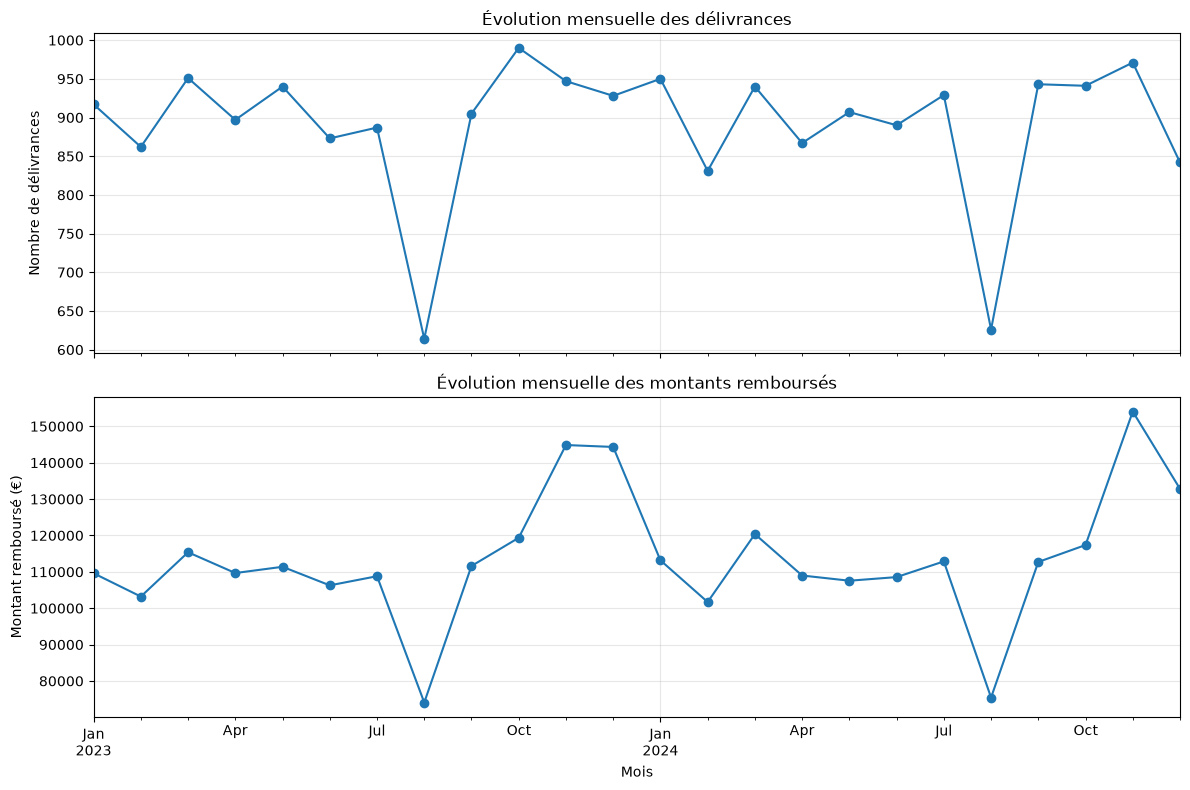


=== 2. ANALYSE PAR FAMILLE DE PRODUITS ===


,nb_delivrances,montant_total,part_montant_pct
famille,,,
famille b,4316,559768.81,20.55
famille d,4283,545399.3,20.02
famille c,4266,538587.44,19.77
famille e,4229,537432.35,19.73
famille a,4205,535813.39,19.67
Inconnue,49,7091.88,0.26


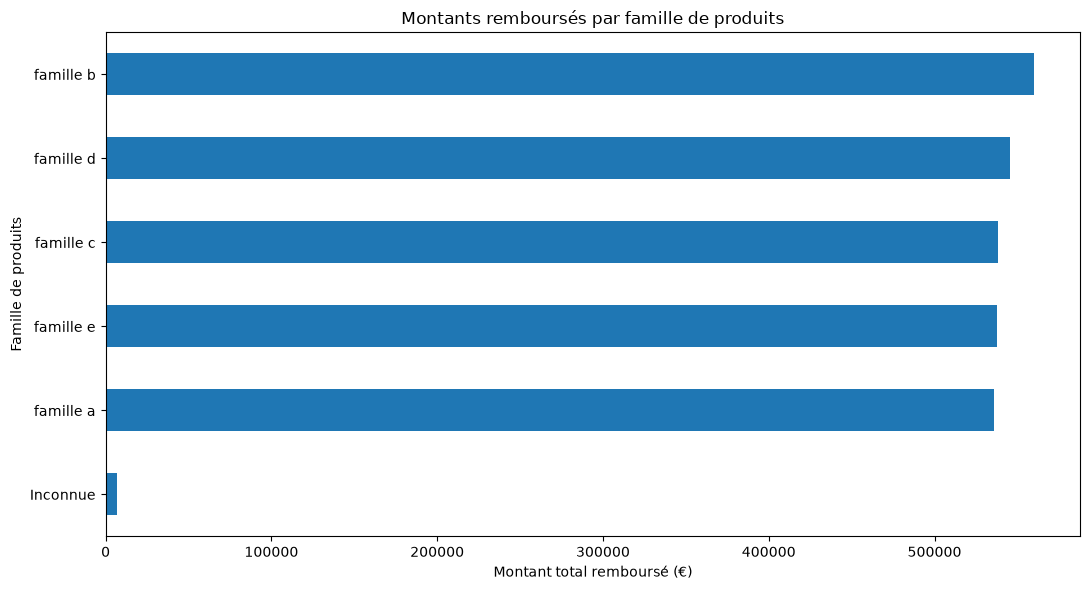


=== 3. ANALYSE PAR SEGMENT DE PATIENTS ===


,nb_delivrances,nb_patients,montant_total,part_delivrances_pct
segment,,,,
particulier,11067,1751,1417990.92,51.84
professionnel,7287,1159,930496.56,34.13
association,2994,487,375605.69,14.02


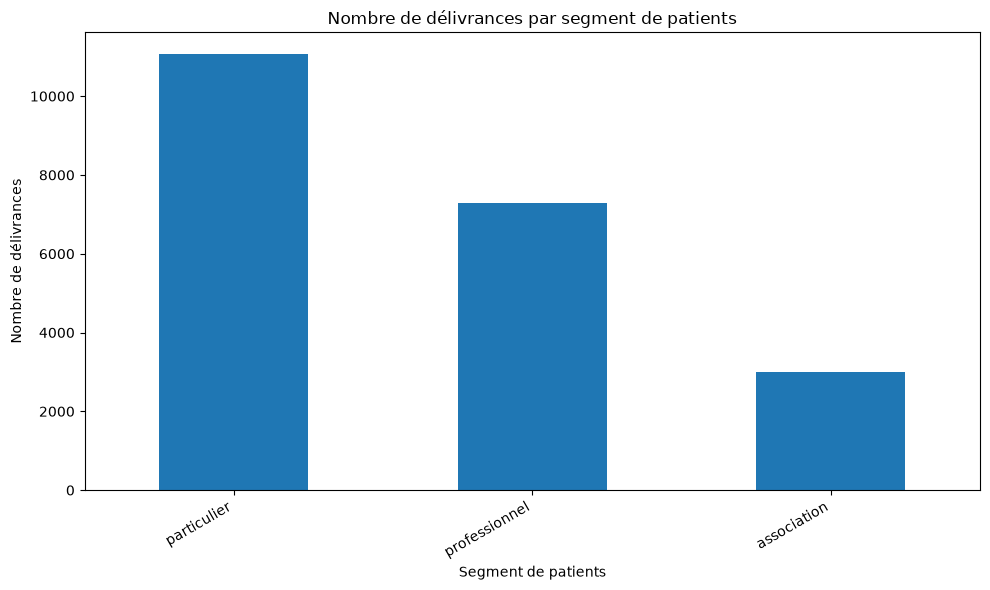


=== 4. ANALYSE PAR OFFICINE ===


,nb_delivrances,montant_total,part_montant_pct
id_officine,,,
OFF07,1979,257582.15,9.46
OFF04,1979,255141.09,9.37
OFF99,1983,253221.5,9.3
OFF03,1968,251090.33,9.22
OFF01,1938,250325.12,9.19
OFF08,1966,249729.24,9.17
OFF06,1970,248256.89,9.11
OFF05,1963,246340.08,9.04
OFF10,1852,238923.36,8.77


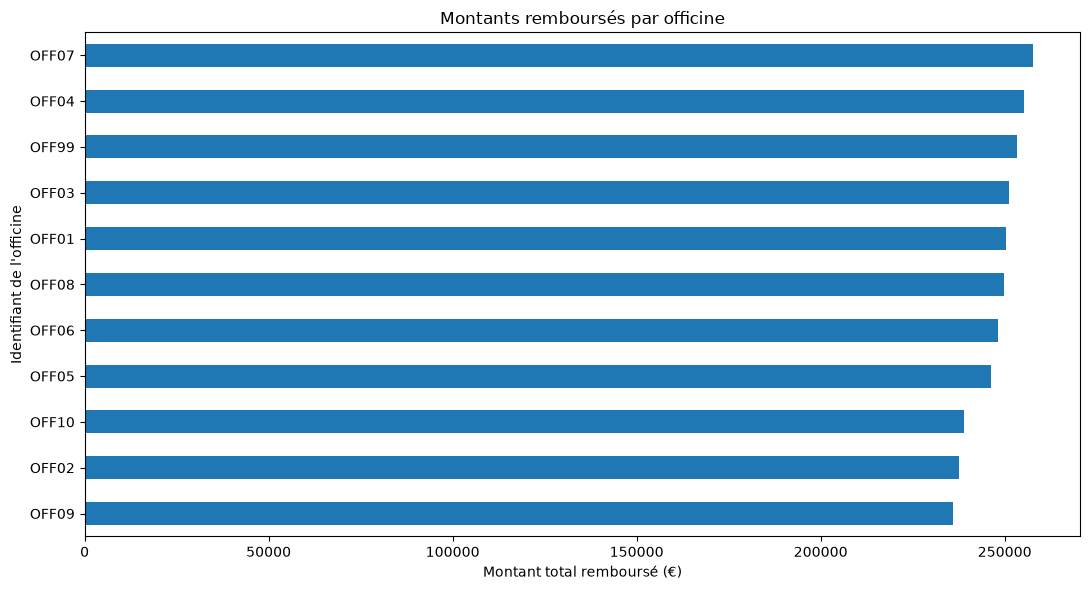


=== 5. ANALYSE DÉTAILLÉE DES PRODUITS ===

=== TOP 10 DES PRODUITS PAR NOMBRE DE BOÎTES ===


,id_produit,libelle,famille,nb_delivrances,nb_boites,montant_rembourse,nb_patients,part_reseau_pct
218,PRD0219,Del-0219,famille e,90,317,11312.8,89,0.42
170,PRD0171,Del-0171,famille b,94,284,12177.19,94,0.45
270,PRD0271,Del-0271,famille b,80,284,10971.53,78,0.4
220,PRD0221,Del-0221,famille b,82,278,11052.37,82,0.41
41,PRD0042,Del-0042,famille c,91,276,12451.46,89,0.46
242,PRD0243,Del-0243,famille d,88,276,11370.96,85,0.42
43,PRD0044,Del-0044,famille e,70,272,8258.85,69,0.3
128,PRD0129,Del-0129,famille e,81,268,9885.13,81,0.36
58,PRD0059,Del-0059,famille e,84,268,10436.2,83,0.38
148,PRD0149,Del-0149,famille e,85,266,11486.44,83,0.42


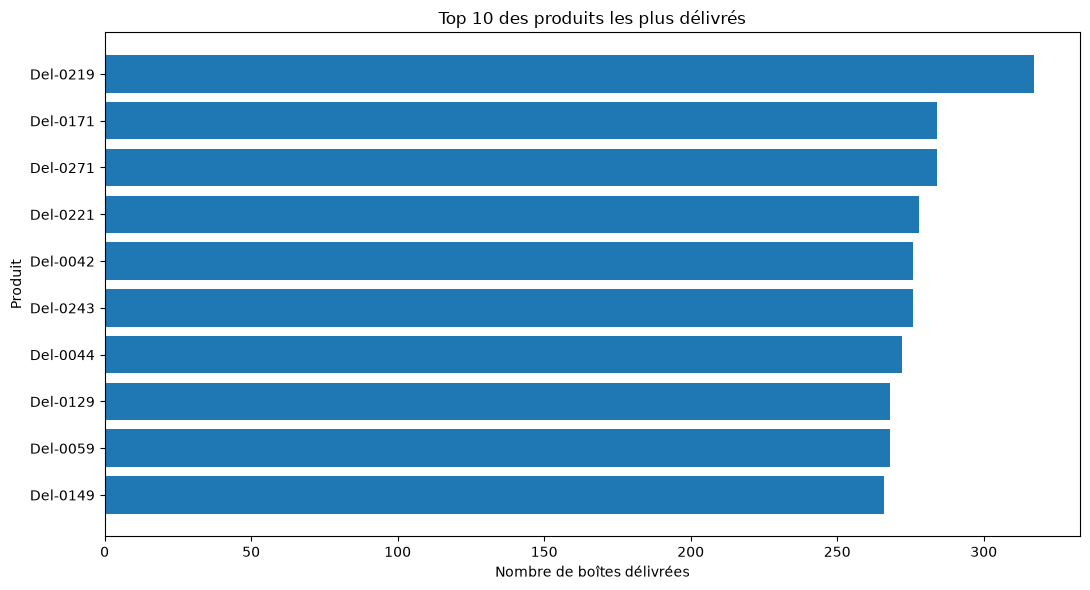


=== TOP 10 DES PRODUITS PAR REMBOURSEMENT ===


,id_produit,libelle,famille,nb_delivrances,nb_boites,montant_rembourse,nb_patients,part_reseau_pct
41,PRD0042,Del-0042,famille c,91,276,12451.46,89,0.46
170,PRD0171,Del-0171,famille b,94,284,12177.19,94,0.45
85,PRD0086,Del-0086,famille b,91,260,12100.89,91,0.44
148,PRD0149,Del-0149,famille e,85,266,11486.44,83,0.42
257,PRD0258,Del-0258,famille d,82,249,11426.41,82,0.42
242,PRD0243,Del-0243,famille d,88,276,11370.96,85,0.42
218,PRD0219,Del-0219,famille e,90,317,11312.8,89,0.42
81,PRD0082,Del-0082,famille c,80,262,11281.61,80,0.41
235,PRD0236,Del-0236,famille b,84,259,11162.2,84,0.41
111,PRD0112,Del-0112,famille c,80,222,11109.23,79,0.41


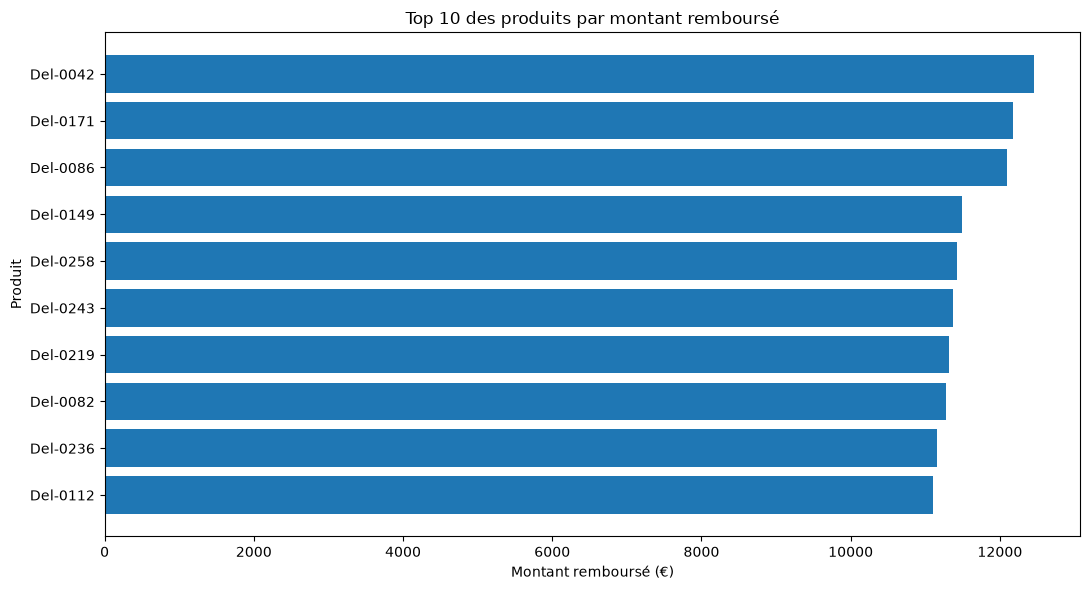


=== TOP 3 DES PRODUITS PAR OFFICINE ===


,id_officine,id_produit,libelle,nb_delivrances,nb_boites,montant_rembourse
171,OFF01,PRD0172,Del-0172,10,53,1025.15
23,OFF01,PRD0024,Del-0024,8,51,916.45
55,OFF01,PRD0056,Del-0056,9,50,505.16
528,OFF02,PRD0219,Del-0219,6,60,322.59
397,OFF02,PRD0088,Del-0088,5,49,604.94
443,OFF02,PRD0134,Del-0134,12,43,1409.28
670,OFF03,PRD0051,Del-0051,16,53,1766.22
876,OFF03,PRD0257,Del-0257,7,47,1159.03
890,OFF03,PRD0271,Del-0271,4,45,626.33
1042,OFF04,PRD0113,Del-0113,19,53,2485.07



SYNTHÈSE — RÉPONSE À NOTRE PROBLÉMATIQUE

Nombre total de délivrances : 21,348
Montant total enregistré : 2,724,093.17 €
Période étudiée : 2023-01-01 au 2024-12-30

1. ÉVOLUTION TEMPORELLE
Mois avec le plus de délivrances : 10/2023 (990)
Mois avec le moins de délivrances : 08/2023 (614)

2. FAMILLES DE PRODUITS
Famille avec le montant le plus élevé : famille b
Part des remboursements : 20.55 %

3. SEGMENTS DE PATIENTS
Segment avec le plus de délivrances : particulier
Part des délivrances : 51.84 %

4. OFFICINES
Officine avec le montant le plus élevé : OFF07
Part des remboursements : 9.46 %

5. PRODUITS — UTILISATION CLIENT
Nombre de produits référencés observés : 310
Nombre total de boîtes sur les produits connus : 65052
Délivrances avec produit inconnu : 49
Produit le plus délivré : Del-0219
Nombre de boîtes : 317
Produit avec le montant remboursé le plus élevé : Del-0042
Montant remboursé : 12,451.46 €

Analyses et graphiques exportés avec succès !


In [12]:

# ============================================================
# 7. ANALYSE MÉTIER — RÉPONSE À NOTRE PROBLÉMATIQUE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Charger le jeu final nettoyé depuis le fichier Parquet
fichier_final = GROUP_DIR / "processed" / "delivrances_preparees.parquet"

jeu_final = pd.read_parquet(fichier_final)

# Créer une copie pour les analyses
df = jeu_final.copy()

print("Jeu final chargé avec succès !")
print("Nombre de délivrances :", len(df))
print("Nombre de colonnes :", len(df.columns))

display(df.head())

# Sécuriser les types
df["date_evenement"] = pd.to_datetime(
    df["date_evenement"], errors="coerce"
)

df["montant_rembourse_eur"] = pd.to_numeric(
    df["montant_rembourse_eur"], errors="coerce"
)

df["boites_delivrees"] = pd.to_numeric(
    df["boites_delivrees"], errors="coerce"
)

# Vérifier la suppression des dates invalides
assert df["date_evenement"].notna().all(), (
    "Il reste des dates invalides dans le jeu final."
)

# Créer le dossier des graphiques
GRAPHIQUES_DIR = PROCESSED_DIR / "graphiques"
GRAPHIQUES_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 8. ÉVOLUTION MENSUELLE
# ============================================================

print("\n=== 1. ÉVOLUTION TEMPORELLE ===")

mensuel = (
    df.groupby(
        pd.Grouper(key="date_evenement", freq="MS")
    )
    .agg(
        nb_delivrances=("id_produit", "size"),
        montant_total=("montant_rembourse_eur", "sum")
    )
)

display(mensuel)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

mensuel["nb_delivrances"].plot(
    ax=axes[0], marker="o"
)

axes[0].set_title("Évolution mensuelle des délivrances")
axes[0].set_ylabel("Nombre de délivrances")
axes[0].grid(alpha=0.3)

mensuel["montant_total"].plot(
    ax=axes[1], marker="o"
)

axes[1].set_title("Évolution mensuelle des montants remboursés")
axes[1].set_ylabel("Montant remboursé (€)")
axes[1].set_xlabel("Mois")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "evolution_mensuelle.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. ANALYSE PAR FAMILLE DE PRODUITS
# ============================================================

print("\n=== 2. ANALYSE PAR FAMILLE DE PRODUITS ===")

familles = (
    df.assign(
        famille=df["famille"].fillna("Inconnue")
    )
    .groupby("famille")
    .agg(
        nb_delivrances=("id_produit", "size"),
        montant_total=("montant_rembourse_eur", "sum")
    )
    .sort_values("montant_total", ascending=False)
)

total_rembourse = familles["montant_total"].sum()

familles["part_montant_pct"] = (
    familles["montant_total"] / total_rembourse * 100
    if total_rembourse != 0
    else 0
).round(2)

display(familles)

plt.figure(figsize=(11, 6))

familles["montant_total"].sort_values().plot(
    kind="barh"
)

plt.title("Montants remboursés par famille de produits")
plt.xlabel("Montant total remboursé (€)")
plt.ylabel("Famille de produits")
plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "remboursements_familles.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. ANALYSE PAR SEGMENT DE PATIENTS
# ============================================================

print("\n=== 3. ANALYSE PAR SEGMENT DE PATIENTS ===")

segments = (
    df.assign(
        segment=df["segment"].fillna("Inconnu")
    )
    .groupby("segment")
    .agg(
        nb_delivrances=("id_patient", "size"),
        nb_patients=("id_patient", "nunique"),
        montant_total=("montant_rembourse_eur", "sum")
    )
    .sort_values("nb_delivrances", ascending=False)
)

segments["part_delivrances_pct"] = (
    segments["nb_delivrances"] / len(df) * 100
).round(2)

display(segments)

plt.figure(figsize=(10, 6))

segments["nb_delivrances"].plot(kind="bar")

plt.title("Nombre de délivrances par segment de patients")
plt.xlabel("Segment de patients")
plt.ylabel("Nombre de délivrances")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "delivrances_segments.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. ANALYSE PAR OFFICINE
# ============================================================

print("\n=== 4. ANALYSE PAR OFFICINE ===")

officines_analyse = (
    df.groupby("id_officine", dropna=False)
    .agg(
        nb_delivrances=("id_produit", "size"),
        montant_total=("montant_rembourse_eur", "sum")
    )
    .sort_values("montant_total", ascending=False)
)

total_officines = officines_analyse["montant_total"].sum()

officines_analyse["part_montant_pct"] = (
    officines_analyse["montant_total"] / total_officines * 100
    if total_officines != 0
    else 0
).round(2)

display(officines_analyse)

plt.figure(figsize=(11, 6))

officines_analyse["montant_total"].sort_values().plot(
    kind="barh"
)

plt.title("Montants remboursés par officine")
plt.xlabel("Montant total remboursé (€)")
plt.ylabel("Identifiant de l'officine")
plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "remboursements_officines.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. NOUVEAU — ANALYSE DÉTAILLÉE DES PRODUITS
# ============================================================

print("\n=== 5. ANALYSE DÉTAILLÉE DES PRODUITS ===")

# Exclure uniquement les références inconnues
# de cette analyse détaillée, pas du jeu final
produits_connus = df[
    df["id_produit"].notna()
    & ~df["produit_inconnu"].fillna(True)
].copy()

# Calculer les indicateurs par produit
analyse_produits = (
    produits_connus
    .groupby(
        ["id_produit", "libelle", "famille"],
        dropna=False
    )
    .agg(
        nb_delivrances=("id_delivrance", "size"),
        nb_boites=("boites_delivrees", "sum"),
        montant_rembourse=("montant_rembourse_eur", "sum"),
        nb_patients=("id_patient", "nunique")
    )
    .reset_index()
)

# Part des montants par produit dans le total du réseau
montant_reseau = df["montant_rembourse_eur"].sum()

analyse_produits["part_reseau_pct"] = (
    analyse_produits["montant_rembourse"]
    / montant_reseau * 100
    if montant_reseau != 0
    else 0
).round(2)


# ============================================================
# 13. TOP 10 DES PRODUITS LES PLUS DÉLIVRÉS
# ============================================================

print("\n=== TOP 10 DES PRODUITS PAR NOMBRE DE BOÎTES ===")

top_produits = (
    analyse_produits
    .sort_values("nb_boites", ascending=False)
    .head(10)
)

display(top_produits)

plt.figure(figsize=(11, 6))

plt.barh(
    top_produits["libelle"].iloc[::-1].astype(str),
    top_produits["nb_boites"].iloc[::-1]
)

plt.title("Top 10 des produits les plus délivrés")
plt.xlabel("Nombre de boîtes délivrées")
plt.ylabel("Produit")
plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "top_10_produits_boites.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. TOP 10 DES PRODUITS PAR MONTANT REMBOURSÉ
# ============================================================

print("\n=== TOP 10 DES PRODUITS PAR REMBOURSEMENT ===")

top_remboursements = (
    analyse_produits
    .sort_values("montant_rembourse", ascending=False)
    .head(10)
)

display(top_remboursements)

plt.figure(figsize=(11, 6))

plt.barh(
    top_remboursements["libelle"].iloc[::-1].astype(str),
    top_remboursements["montant_rembourse"].iloc[::-1]
)

plt.title("Top 10 des produits par montant remboursé")
plt.xlabel("Montant remboursé (€)")
plt.ylabel("Produit")
plt.tight_layout()

plt.savefig(
    GRAPHIQUES_DIR / "top_10_produits_remboursements.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. TOP 3 DES PRODUITS PAR OFFICINE
# ============================================================

print("\n=== TOP 3 DES PRODUITS PAR OFFICINE ===")

produits_officines = (
    produits_connus
    .groupby(
        ["id_officine", "id_produit", "libelle"],
        dropna=False
    )
    .agg(
        nb_delivrances=("id_delivrance", "size"),
        nb_boites=("boites_delivrees", "sum"),
        montant_rembourse=("montant_rembourse_eur", "sum")
    )
    .reset_index()
)

top_par_officine = (
    produits_officines
    .sort_values(
        ["id_officine", "nb_boites"],
        ascending=[True, False]
    )
    .groupby("id_officine", group_keys=False)
    .head(3)
)

display(top_par_officine)


# ============================================================
# 16. SYNTHÈSE AUTOMATIQUE DES RÉSULTATS
# ============================================================

print("\n" + "=" * 60)
print("SYNTHÈSE — RÉPONSE À NOTRE PROBLÉMATIQUE")
print("=" * 60)

print(f"\nNombre total de délivrances : {len(df):,}")

print(
    f"Montant total enregistré : "
    f"{df['montant_rembourse_eur'].sum():,.2f} €"
)

print(
    f"Période étudiée : "
    f"{df['date_evenement'].min().date()} "
    f"au {df['date_evenement'].max().date()}"
)

# Évolution temporelle
if not mensuel.empty:
    mois_max = mensuel["nb_delivrances"].idxmax()
    mois_min = mensuel["nb_delivrances"].idxmin()

    print("\n1. ÉVOLUTION TEMPORELLE")

    print(
        f"Mois avec le plus de délivrances : "
        f"{mois_max.strftime('%m/%Y')} "
        f"({int(mensuel.loc[mois_max, 'nb_delivrances'])})"
    )

    print(
        f"Mois avec le moins de délivrances : "
        f"{mois_min.strftime('%m/%Y')} "
        f"({int(mensuel.loc[mois_min, 'nb_delivrances'])})"
    )

# Familles
if not familles.empty:
    print("\n2. FAMILLES DE PRODUITS")

    print(
        "Famille avec le montant le plus élevé :",
        familles.index[0]
    )

    print(
        "Part des remboursements :",
        f"{familles.iloc[0]['part_montant_pct']:.2f} %"
    )

# Segments
if not segments.empty:
    print("\n3. SEGMENTS DE PATIENTS")

    print(
        "Segment avec le plus de délivrances :",
        segments.index[0]
    )

    print(
        "Part des délivrances :",
        f"{segments.iloc[0]['part_delivrances_pct']:.2f} %"
    )

# Officines
if not officines_analyse.empty:
    print("\n4. OFFICINES")

    print(
        "Officine avec le montant le plus élevé :",
        officines_analyse.index[0]
    )

    print(
        "Part des remboursements :",
        f"{officines_analyse.iloc[0]['part_montant_pct']:.2f} %"
    )

# Nouveaux résultats produits
print("\n5. PRODUITS — UTILISATION CLIENT")

print(
    "Nombre de produits référencés observés :",
    analyse_produits["id_produit"].nunique()
)

print(
    "Nombre total de boîtes sur les produits connus :",
    int(produits_connus["boites_delivrees"].sum())
)

print(
    "Délivrances avec produit inconnu :",
    int(df["produit_inconnu"].fillna(False).sum())
)

if not top_produits.empty:
    print(
        "Produit le plus délivré :",
        top_produits.iloc[0]["libelle"]
    )

    print(
        "Nombre de boîtes :",
        int(top_produits.iloc[0]["nb_boites"])
    )

if not top_remboursements.empty:
    print(
        "Produit avec le montant remboursé le plus élevé :",
        top_remboursements.iloc[0]["libelle"]
    )

    print(
        "Montant remboursé :",
        f"{top_remboursements.iloc[0]['montant_rembourse']:,.2f} €"
    )


# ============================================================
# 17. EXPORT DES RÉSULTATS MÉTIER
# ============================================================

mensuel.to_csv(
    PROCESSED_DIR / "analyse_mensuelle.csv",
    encoding="utf-8-sig", sep=";"
)

familles.to_csv(
    PROCESSED_DIR / "analyse_familles.csv",
    encoding="utf-8-sig", sep=";"
)

segments.to_csv(
    PROCESSED_DIR / "analyse_segments.csv",
    encoding="utf-8-sig", sep=";"
)

officines_analyse.to_csv(
    PROCESSED_DIR / "analyse_officines.csv",
    encoding="utf-8-sig", sep=";"
)

# Nouveaux exports produits
analyse_produits.to_csv(
    PROCESSED_DIR / "analyse_produits.csv",
    index=False, encoding="utf-8-sig", sep=";"
)

top_par_officine.to_csv(
    PROCESSED_DIR / "top_produits_par_officine.csv",
    index=False, encoding="utf-8-sig", sep=";"
)

print("\nAnalyses et graphiques exportés avec succès !")


### Limites assumées

1. Données temporelles incomplètes : certaines délivrances possèdent une date manquante ou invalide. Nous les avons conservées pour les analyses globales, mais elles ne peuvent pas être prises en compte dans les analyses chronologiques. Les tendances temporelles peuvent donc être légèrement sous-estimées.

2. Informations patients et produits incomplètes : certains âges, certaines durées de traitement et certains coûts de référence restent manquants. Nous avons choisi de ne pas inventer de valeurs, ce qui garantit la transparence du traitement, mais limite certaines analyses détaillées.
 
3. Références produits inconnues et interprétation métier : certaines délivrances font référence à des produits absents du référentiel. Nous les avons conservées pour ne pas perdre d'activité, mais elles ne peuvent pas être classées précisément par famille de produits. Par ailleurs, les quantités nulles et les statuts nécessitent une validation métier pour interpréter correctement les délivrances réellement effectuées.

---
## 6. Contrôle avant dépôt

La cellule suivante vérifie que votre rendu est complet. Exécutez-la avant de déposer.

Le dépôt est attendu le **jour 5 à 13 h 30**, avant la reprise de l'après-midi : votre
composant PySpark se termine le matin même. Prévoyez trente minutes pour la mise en forme,
pas cinq.

In [17]:
checks = {
    'requirements.txt présent': (ROOT / 'requirements.txt').exists(),
    'README.md présent': (ROOT / 'README.md').exists(),
    'dossier src/ non vide': (ROOT / 'src').exists() and any((ROOT / 'src').glob('*.py')),
    'jeu final produit': (any(PROCESSED_DIR.glob('*.parquet'))
                          or any(PROCESSED_DIR.glob('*.csv'))),
    'note méthodologique': any(ROOT.glob('note_methodologique.*')),
    'support de soutenance': any(ROOT.glob('soutenance.*')),
}

width = max(len(label) for label in checks)
for label, is_ok in checks.items():
    print(f"{label:<{width}}  {'OK' if is_ok else 'MANQUANT'}")

if all(checks.values()):
    print('\nRendu complet.')
else:
    print('\nIl manque des éléments listés ci-dessus.')

requirements.txt présent  OK
README.md présent         MANQUANT
dossier src/ non vide     OK
jeu final produit         OK
note méthodologique       MANQUANT
support de soutenance     MANQUANT

Il manque des éléments listés ci-dessus.


---
## 7. Préparation aux questions

Rédigez votre réponse à chacune de ces questions **avant** la soutenance. Elles seront
posées dans une formulation proche.

1. Pourquoi avoir imputé cette colonne de cette façon plutôt qu'autrement ?
2. Vous avez écarté un certain pourcentage de lignes. Comment savez-vous qu'il ne
   s'agissait pas d'observations légitimes ?
3. Combien de colonnes votre encodage a-t-il produit ? Quelles conséquences ?
4. À partir de quel volume votre pipeline Pandas cesserait-il de fonctionner ?
5. Si je vous fournis demain un nouveau fichier source au même format, que faut-il faire ?
6. Montrez-moi la ligne de code qui traite ce cas particulier et expliquez-la.
7. Quelle est la principale limite de votre jeu de données final ?

> **Chaque membre du groupe doit pouvoir répondre sur l'intégralité du travail**, y compris
> les parties qu'il n'a pas présentées. Les questions sont posées individuellement.